# Preprocessing dan Pengelompokan Dataset Laptop Amazon

1. Membaca dataset laptop Amazon
2. Preprocessing data (seleksi kolom, ekstraksi fitur, pembersihan, encoding)
3. Normalisasi fitur numerik
4. Pengelompokan menggunakan algoritma K-Medoids
5. Evaluasi dan visualisasi hasil clustering

---
## 1. Import Library dan Membaca Data

In [ ]:
import pandas as pd
import numpy as np
import json
import re

# Library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# !pip install numpy==1.26.4
# !pip install scikit-learn-extra

# Library machine learning
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import silhouette_score
from sklearn_extra.cluster import KMedoids


In [ ]:
# Membaca dataset dari file CSV lokal
df_laptop = pd.read_csv("amazon_laptop_reviews.csv")

print("Ukuran dataset awal:", df_laptop.shape)
display(df_laptop.head())

Ukuran dataset awal: (32759, 31)


,rating,title_x,text,images_x,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,...,details,bought_together,subtitle,author,num_reviews,avg_helpful_votes,id,os,color,brand
0,5,Fast!,I have been using laptops for the past 30 year...,[],B089HR6CQP,B08G5F3X8F,AHV6QCNBJNSGLATP56JAWJ3C4G2A,1.600000e+12,0,False,...,"{""Standing screen display size"": ""15.6 Inches""...",NaN,NaN,NaN,114,4.86,0,Windows 10 Home,Black,Dell
1,5,Works Great - No Problems - Great Value for Price,"I read a bunch of negative reviews, so I wante...",[],B089HR6CQP,B08G5F3X8F,AFNC5IF4WHTXND7NFTXIKBHQKZ7A,1.630000e+12,0,True,...,"{""Standing screen display size"": ""15.6 Inches""...",NaN,NaN,NaN,114,4.86,1,Windows 10 Home,Black,Dell
2,5,Excellent gaming computer for the price,"Runs smooth, fast, and works well for gaming. ...",[],B089HR6CQP,B08G5F3X8F,AFOPOR5RN7JTWVXC72ITV7XJXIXA,1.610000e+12,0,True,...,"{""Standing screen display size"": ""15.6 Inches""...",NaN,NaN,NaN,114,4.86,2,Windows 10 Home,Black,Dell
3,1,Overheating on setup,I'm impressed. I've never seen a computer so w...,"[{'attachment_type': 'IMAGE', 'large_image_url...",B089HR6CQP,B08G5F3X8F,AEQBZ7WR6AYATE3WRWD2LVD74FOA,1.630000e+12,0,True,...,"{""Standing screen display size"": ""15.6 Inches""...",NaN,NaN,NaN,114,4.86,3,Windows 10 Home,Black,Dell
4,1,Don’t buy,"I bought 2 of these laptops, asked for replace...",[],B089HR6CQP,B08G5F3X8F,AGLZUC53J6SZNIXLOECZ7GOIZFNQ,1.610000e+12,22,True,...,"{""Standing screen display size"": ""15.6 Inches""...",NaN,NaN,NaN,114,4.86,4,Windows 10 Home,Black,Dell


---
## 2. Seleksi Kolom yang Dibutuhkan

In [ ]:
# Memilih hanya kolom yang relevan
selected_columns = ['user_id', 'parent_asin', 'rating', 'brand', 'price', 'details']
df_selected = df_laptop[selected_columns].copy()

print("Ukuran dataset setelah seleksi kolom:", df_selected.shape)
display(df_selected.head())

Ukuran dataset setelah seleksi kolom: (32759, 6)


,user_id,parent_asin,rating,brand,price,details
0,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B08G5F3X8F,5,Dell,799.0,"{""Standing screen display size"": ""15.6 Inches""..."
1,AFNC5IF4WHTXND7NFTXIKBHQKZ7A,B08G5F3X8F,5,Dell,799.0,"{""Standing screen display size"": ""15.6 Inches""..."
2,AFOPOR5RN7JTWVXC72ITV7XJXIXA,B08G5F3X8F,5,Dell,799.0,"{""Standing screen display size"": ""15.6 Inches""..."
3,AEQBZ7WR6AYATE3WRWD2LVD74FOA,B08G5F3X8F,1,Dell,799.0,"{""Standing screen display size"": ""15.6 Inches""..."
4,AGLZUC53J6SZNIXLOECZ7GOIZFNQ,B08G5F3X8F,1,Dell,799.0,"{""Standing screen display size"": ""15.6 Inches""..."


---
## 3. Ekstraksi Fitur dari Kolom JSON (details)

Kolom `details` berisi data JSON yang menyimpan spesifikasi teknis laptop.
Fitur yang diekstrak: **CPU Model**, **RAM**, dan **Hard Drive**.

In [ ]:
# Mengubah string JSON pada kolom details menjadi dictionary menggunakan json.loads()
df_selected["details"] = df_selected["details"].apply(json.loads)

# Tentukan atribut yang ingin diambil dari details
target_keys = ["CPU Model", "RAM", "Hard Drive"]

# Mengambil hanya key yang diperlukan dari dictionary detail.
def extract_selected_details(detail_dict):
    if isinstance(detail_dict, dict):
        return {k: detail_dict.get(k) for k in target_keys if k in detail_dict}
    return {}

# Ekstraksi atribut dari kolom details
filtered_details = df_selected["details"].apply(extract_selected_details)
filtered_details_df = filtered_details.apply(pd.Series)

# Menggabungkan kolom hasil ekstraksi dengan dataset utama (tanpa kolom details lama)
final_df = pd.concat([df_selected.drop(columns=["details"]), filtered_details_df], axis=1)

print("Ukuran dataset setelah ekstraksi fitur:", final_df.shape)
display(final_df.head())

Ukuran dataset setelah ekstraksi fitur: (32759, 8)


,user_id,parent_asin,rating,brand,price,CPU Model,RAM,Hard Drive
0,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD
1,AFNC5IF4WHTXND7NFTXIKBHQKZ7A,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD
2,AFOPOR5RN7JTWVXC72ITV7XJXIXA,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD
3,AEQBZ7WR6AYATE3WRWD2LVD74FOA,B08G5F3X8F,1,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD
4,AGLZUC53J6SZNIXLOECZ7GOIZFNQ,B08G5F3X8F,1,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD


In [ ]:
# Mengecek jumlah missing value pada setiap kolom
data_missing = final_df.isnull().sum()

print("Missing value per kolom:")
print(data_missing)

Missing value per kolom:
user_id            0
parent_asin        0
rating             0
brand             79
price          16554
CPU Model       2339
RAM             1522
Hard Drive      1613
dtype: int64


In [ ]:
final_df.head()

,user_id,parent_asin,rating,brand,price,CPU Model,RAM,Hard Drive
0,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD
1,AFNC5IF4WHTXND7NFTXIKBHQKZ7A,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD
2,AFOPOR5RN7JTWVXC72ITV7XJXIXA,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD
3,AEQBZ7WR6AYATE3WRWD2LVD74FOA,B08G5F3X8F,1,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD
4,AGLZUC53J6SZNIXLOECZ7GOIZFNQ,B08G5F3X8F,1,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD


---
## 4. Pembersihan Kolom Brand

Standardisasi nama brand: menyamakan kapitalisasi dan menggabungkan variasi nama yang sama menjadi satu format standar.

In [ ]:
# Standardisasi kapitalisasi nama brand
final_df['brand_clean'] = (final_df['brand']
    .str.strip()   # Menghapus spasi di awal/akhir
    .str.title()   # Mengubah ke format Title Case (misal: 'hp' → 'Hp')
)

# Ganti nama brand yang memiliki variasi penulisan
replace_dict = {
    'Hp': 'HP',
    'Hewlett Packard': 'HP',
    'Hewlett Packard Enterprise': 'HP',
    'Omen': 'HP',
    'Elitebook': 'HP',
    'Asus': 'ASUS',
    'Asus Laptops': 'ASUS',
    'Acer Gateway': 'Acer',
    'Gigabyte': 'GIGABYTE',
    'Aorus': 'GIGABYTE',
    'Lenovo Group Limited': 'Lenovo',
    'Latitude': 'Dell',
}

# Menghapus baris dengan brand kosong atau berisi angka (bukan nama brand valid)
final_df = final_df[final_df['brand_clean'].notna()]
final_df = final_df[~final_df['brand_clean'].str.isnumeric()]

# Mengganti nama brand sesuai kamus standardisasi
final_df['brand_clean'] = final_df['brand_clean'].replace(replace_dict)

print("Ukuran dataset setelah pembersihan brand:", final_df.shape)
print("Jumlah brand unik:", len(final_df['brand_clean'].unique()))

# Daftar brand laptop yang dianggap valid
valid_brands = [
    'Acer', 'ASUS', 'Alienware', 'Apple', 'Computer Upgrade King',
    'Cyberpowerpc', 'Dell', 'Dynabook', 'Eluktronics', 'Evga', 'Evoo',
    'GIGABYTE', 'Gateway', 'HP', 'Huawei', 'Ibuypower', 'Lenovo', 'Lg',
    'Maingear', 'Microsoft', 'Msi', 'Powerspec', 'Razer', 'Samsung',
    'Sony', 'Toshiba', 'Xotic Pc'
]

# Memfilter dataset agar hanya menyimpan brand yang valid
final_df = final_df[final_df['brand_clean'].isin(valid_brands)]

print("\nUkuran dataset setelah filter brand valid:", final_df.shape)
print("Jumlah brand valid tersisa:", len(final_df['brand_clean'].unique()))

# Menampilkan daftar brand valid dalam format tabel 3 kolom
brands_array = np.array(sorted(final_df['brand_clean'].unique()))
brands_array = brands_array.reshape(-1, 3)
for row in brands_array:
    print("{:<20} {:<20} {:<20}".format(*row))

Ukuran dataset setelah pembersihan brand: (32677, 9)
Jumlah brand unik: 39

Ukuran dataset setelah filter brand valid: (32591, 9)
Jumlah brand valid tersisa: 27
ASUS                 Acer                 Alienware           
Apple                Computer Upgrade King Cyberpowerpc        
Dell                 Dynabook             Eluktronics         
Evga                 Evoo                 GIGABYTE            
Gateway              HP                   Huawei              
Ibuypower            Lenovo               Lg                  
Maingear             Microsoft            Msi                 
Powerspec            Razer                Samsung             
Sony                 Toshiba              Xotic Pc            


In [ ]:
final_df.head()

,user_id,parent_asin,rating,brand,price,CPU Model,RAM,Hard Drive,brand_clean
0,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD,Dell
1,AFNC5IF4WHTXND7NFTXIKBHQKZ7A,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD,Dell
2,AFOPOR5RN7JTWVXC72ITV7XJXIXA,B08G5F3X8F,5,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD,Dell
3,AEQBZ7WR6AYATE3WRWD2LVD74FOA,B08G5F3X8F,1,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD,Dell
4,AGLZUC53J6SZNIXLOECZ7GOIZFNQ,B08G5F3X8F,1,Dell,799.0,Core i5,8 GB DDR4,512 GB SSD,Dell


---
## 5. Penanganan Missing Value

Strategi pengisian missing value:
- **CPU Model**: diisi dengan `'Unknown'`
- **RAM** dan **Hard Drive**: diisi dengan nilai **modus** (nilai yang paling sering muncul)
- **Price**: diisi dengan nilai **median**

In [ ]:
# Mengisi missing value pada CPU Model dengan label 'Unknown'
final_df['CPU Model'].fillna('Unknown', inplace=True)

# RAM dan Hard Drive: isi dengan nilai modus (paling sering muncul)
final_df['RAM'].fillna(final_df['RAM'].mode()[0], inplace=True)
final_df['Hard Drive'].fillna(final_df['Hard Drive'].mode()[0], inplace=True)

# Mengubah kolom price ke tipe numerik; nilai yang tidak valid dijadikan NaN
final_df['price'] = pd.to_numeric(final_df['price'], errors='coerce')

# Mengisi missing value pada price menggunakan nilai median
median_price = final_df['price'].median()
print("Median harga:", median_price)
final_df['price'].fillna(median_price, inplace=True)

print("\nUkuran dataset setelah penanganan missing value:", final_df.shape)

# Verifikasi tidak ada missing value tersisa
print("\nMissing value setelah penanganan:")
print(final_df.isnull().sum())

Median harga: 1059.88

Ukuran dataset setelah penanganan missing value: (32591, 9)

Missing value setelah penanganan:
user_id        0
parent_asin    0
rating         0
brand          0
price          0
CPU Model      0
RAM            0
Hard Drive     0
brand_clean    0
dtype: int64


/tmp/ipykernel_2395/2135576702.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df['CPU Model'].fillna('Unknown', inplace=True)
/tmp/ipykernel_2395/2135576702.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)',

---
## 6. Konversi RAM dan Hard Drive ke Numerik (satuan GB)

Kolom RAM dan Hard Drive berisi teks seperti `'8 GB'`, `'512 GB'`, atau `'1 TB'`.
Fungsi di bawah mengekstrak angka dan mengkonversinya ke satuan GB.

In [ ]:
def extract_capacity_in_gb(value):
    """
    Mengekstrak kapasitas penyimpanan dari string teks dan mengkonversinya ke GB.

    Contoh input  : '16 GB', '1 TB', '512 MB'
    Contoh output : 16.0, 1000.0, 0.5
    """
    if pd.isnull(value):
        return None

    text = str(value).upper().strip()  # Normalisasi teks ke huruf kapital
    match = re.search(r'(\d+(?:\.\d+)?)', text)  # Ekstrak angka (termasuk desimal)

    if not match:
        return None  # Kembalikan None jika tidak ada angka yang ditemukan

    num = float(match.group(1))

    # Konversi satuan ke GB
    if 'TB' in text:
        num *= 1000       # 1 TB = 1000 GB
    elif 'MB' in text:
        num /= 1024       # 1 MB = 1/1024 GB
    elif 'KB' in text:
        num /= (1024 * 1024)
    # Jika sudah GB, tidak perlu konversi

    return round(num, 2)

# Menerapkan fungsi konversi pada kolom RAM dan Hard Drive
final_df['RAM_clean']       = final_df['RAM'].apply(extract_capacity_in_gb)
final_df['HardDrive_clean'] = final_df['Hard Drive'].apply(extract_capacity_in_gb)

# Membulatkan ke bilangan bulat dan mengubah tipe data ke integer nullable
final_df['RAM_clean']       = final_df['RAM_clean'].round(0).astype('Int64')
final_df['HardDrive_clean'] = final_df['HardDrive_clean'].round(0).astype('Int64')

display(final_df[['RAM', 'RAM_clean', 'Hard Drive', 'HardDrive_clean']].head(10))

,RAM,RAM_clean,Hard Drive,HardDrive_clean
0,8 GB DDR4,8,512 GB SSD,512
1,8 GB DDR4,8,512 GB SSD,512
2,8 GB DDR4,8,512 GB SSD,512
3,8 GB DDR4,8,512 GB SSD,512
4,8 GB DDR4,8,512 GB SSD,512
5,8 GB DDR4,8,512 GB SSD,512
6,8 GB DDR4,8,512 GB SSD,512
7,8 GB DDR4,8,512 GB SSD,512
8,8 GB DDR4,8,512 GB SSD,512
9,8 GB DDR4,8,512 GB SSD,512


---
## 7. Filter Nilai RAM dan Hard Drive yang Valid

Menghapus baris dengan nilai tidak wajar:
- **RAM**: 2 GB – 64 GB
- **Hard Drive**: 64 GB – 4000 GB

In [ ]:
# Menampilkan jumlah dan daftar nilai unik untuk Hard Drive dan RAM
for kolom in ['HardDrive_clean', 'RAM_clean']:
    nilai_unik = final_df[kolom].unique()

    print(f"Jumlah {kolom}:", len(nilai_unik))
    print(f"\nDaftar {kolom}:")
    print(nilai_unik)
    print("-" * 40)

Jumlah HardDrive_clean: 45

Daftar HardDrive_clean:
<IntegerArray>
[    512,       0,    1000,      32,     256,    <NA>,    1128,    4000,
    2000,      16,  128000,       4,     500,     240,     128,    1280,
    1256,    1512,     250,  256000,    1024,     750,    1500, 1000000,
       1,       2,     200,    1200,  512000,      64,    3000,    2256,
    3072,     640,     320,     480,     100,     160,     180,    2512,
  500000,     516,      80,    6000,     120]
Length: 45, dtype: Int64
----------------------------------------
Jumlah RAM_clean: 24

Daftar RAM_clean:
<IntegerArray>
[    8,    16,     4,    12,    32,    44,     2,     5,     6,    20,    64,
     3,    24,   128, 16000,   256,   512,     0,     1,    48,    40, 64000,
  1000,  <NA>]
Length: 24, dtype: Int64
----------------------------------------


In [ ]:
# Menghapus baris dengan nilai NaN pada kolom RAM dan Hard Drive yang sudah dikonversi
final_df = final_df.dropna(subset=['RAM_clean', 'HardDrive_clean'])
print("Ukuran setelah hapus NaN:", final_df.shape)

# Filter RAM: hanya menyimpan nilai antara 2 GB hingga 64 GB
final_df = final_df[(final_df['RAM_clean'] >= 2) & (final_df['RAM_clean'] <= 64)]
# Filter Hard Drive: hanya menyimpan nilai antara 64 GB hingga 4000 GB
final_df = final_df[(final_df['HardDrive_clean'] >= 64) & (final_df['HardDrive_clean'] <= 4000)]

print("Ukuran setelah filter RAM dan Hard Drive valid:", final_df.shape)
print("Nilai unik RAM (GB):", sorted(final_df['RAM_clean'].unique().tolist()))
print("Nilai unik Hard Drive(GB):", sorted(final_df['HardDrive_clean'].astype(int).unique().tolist()))

Ukuran setelah hapus NaN: (30884, 11)
Ukuran setelah filter RAM dan Hard Drive valid: (29201, 11)
Nilai unik RAM (GB): [2, 3, 4, 5, 6, 8, 12, 16, 20, 24, 32, 40, 44, 48, 64]
Nilai unik Hard Drive(GB): [64, 120, 128, 160, 180, 200, 240, 250, 256, 320, 480, 500, 512, 516, 640, 750, 1000, 1024, 1128, 1200, 1256, 1280, 1500, 1512, 2000, 2256, 2512, 3000, 3072, 4000]


---
## 8. Simplifikasi Kategori CPU

Mengkelompokkan nama CPU yang beragam menjadi kategori yang lebih sederhana
(Intel Core Series, AMD Ryzen, Apple Silicon, dan Other).

In [ ]:
def simplify_cpu(text):
    """
    Menyederhanakan nama CPU menjadi kategori utama.

    Contoh: 'Intel Core i7-10750H' → 'Core i7'
             'AMD Ryzen 5 5600H'   → 'Ryzen 5'
    """
    t = text.lower()

    # Intel Core Series
    if "i3" in t: return "Core i3"
    if "i5" in t: return "Core i5"
    if "i7" in t: return "Core i7"
    if "i9" in t: return "Core i9"

    # AMD Ryzen Series
    if "ryzen 3" in t: return "Ryzen 3"
    if "ryzen 5" in t: return "Ryzen 5"
    if "ryzen 7" in t: return "Ryzen 7"
    if "ryzen 9" in t: return "Ryzen 9"

    # Apple Silicon
    if "m1" in t: return "Apple M1"
    if "m2" in t: return "Apple M2"

    # CPU yang tidak masuk kategori di atas
    return "Other"

# Membuat kolom baru berisi kategori CPU yang sudah disederhanakan
final_df["CPU_simplified"] = final_df["CPU Model"].apply(simplify_cpu)

print("Kategori CPU sebelum filter 'Other':", final_df['CPU_simplified'].unique())
print("Ukuran dataset:", final_df.shape)

# Menghapus baris dengan CPU kategori 'Other' (tidak termasuk merek utama)
final_df = final_df[final_df['CPU_simplified'] != 'Other']

print("Kategori CPU setelah filter 'Other':", final_df['CPU_simplified'].unique())
print("Ukuran dataset setelah filter:", final_df.shape)

Kategori CPU sebelum filter 'Other': ['Core i5' 'Other' 'Core i7' 'Ryzen 5' 'Core i9' 'Ryzen 9' 'Ryzen 7'
 'Core i3' 'Ryzen 3']
Ukuran dataset: (29201, 12)
Kategori CPU setelah filter 'Other': ['Core i5' 'Core i7' 'Ryzen 5' 'Core i9' 'Ryzen 9' 'Ryzen 7' 'Core i3'
 'Ryzen 3']
Ukuran dataset setelah filter: (26009, 12)


---
## 9. Finalisasi Kolom: Hapus Kolom Lama dan Ganti Nama

In [ ]:
# Menghapus kolom versi lama yang sudah digantikan oleh kolom yang telah dibersihkan
final_df = final_df.drop(columns=['brand', 'RAM', 'Hard Drive', 'CPU Model'])

# Mengganti nama kolom baru ke nama standar yang lebih ringkas
final_df = final_df.rename(columns={
    'brand_clean'    : 'brand',
    'RAM_clean'      : 'RAM',
    'HardDrive_clean': 'Hard Drive',
    'CPU_simplified' : 'CPU Model'
})

print("Ukuran dataset final setelah preprocessing:", final_df.shape)
display(final_df.head())

Ukuran dataset final setelah preprocessing: (26009, 8)


,user_id,parent_asin,rating,price,brand,RAM,Hard Drive,CPU Model
0,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B08G5F3X8F,5,799.0,Dell,8,512,Core i5
1,AFNC5IF4WHTXND7NFTXIKBHQKZ7A,B08G5F3X8F,5,799.0,Dell,8,512,Core i5
2,AFOPOR5RN7JTWVXC72ITV7XJXIXA,B08G5F3X8F,5,799.0,Dell,8,512,Core i5
3,AEQBZ7WR6AYATE3WRWD2LVD74FOA,B08G5F3X8F,1,799.0,Dell,8,512,Core i5
4,AGLZUC53J6SZNIXLOECZ7GOIZFNQ,B08G5F3X8F,1,799.0,Dell,8,512,Core i5


---
## 10. Label Encoding Kolom Kategorikal

Mengubah kolom `brand` dan `CPU Model` dari teks menjadi angka agar bisa diproses oleh algoritma clustering.

In [ ]:
# Membuat salinan dataframe agar data asli tidak termodifikasi
df_encoded = final_df.copy()

# --- Encoding kolom Brand ---
from sklearn.preprocessing import LabelEncoder
# LabelEncoder untuk kolom brand dan CPU
le_brand = LabelEncoder()
df_encoded['brand'] = le_brand.fit_transform(df_encoded['brand'])
le_cpu = LabelEncoder()
df_encoded['CPU Model'] = le_cpu.fit_transform(df_encoded['CPU Model'])

# Menampilkan pemetaan hasil encoding brand
brand_mapping = pd.DataFrame({
    'Brand'        : le_brand.classes_,
    'Encoded_Brand': le_brand.transform(le_brand.classes_)
})
print("--- Pemetaan Encoding Brand ---")
display(brand_mapping)

# Menampilkan pemetaan hasil encoding CPU
cpu_mapping = pd.DataFrame({
    'CPU Model'        : le_cpu.classes_,
    'Encoded_CPU_Model': le_cpu.transform(le_cpu.classes_)
})
print("\n--- Pemetaan Encoding CPU Model ---")
display(cpu_mapping)

# Menyimpan hasil encoding ke final_df
final_df = df_encoded.copy()

print("\nUkuran dataset setelah encoding:", final_df.shape)
display(final_df.head())

--- Pemetaan Encoding Brand ---


,Brand,Encoded_Brand
0,ASUS,0
1,Acer,1
2,Alienware,2
3,Apple,3
4,Computer Upgrade King,4
5,Cyberpowerpc,5
6,Dell,6
7,Dynabook,7
8,Eluktronics,8
9,Evoo,9



--- Pemetaan Encoding CPU Model ---


,CPU Model,Encoded_CPU_Model
0,Core i3,0
1,Core i5,1
2,Core i7,2
3,Core i9,3
4,Ryzen 3,4
5,Ryzen 5,5
6,Ryzen 7,6
7,Ryzen 9,7



Ukuran dataset setelah encoding: (26009, 8)


,user_id,parent_asin,rating,price,brand,RAM,Hard Drive,CPU Model
0,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B08G5F3X8F,5,799.0,6,8,512,1
1,AFNC5IF4WHTXND7NFTXIKBHQKZ7A,B08G5F3X8F,5,799.0,6,8,512,1
2,AFOPOR5RN7JTWVXC72ITV7XJXIXA,B08G5F3X8F,5,799.0,6,8,512,1
3,AEQBZ7WR6AYATE3WRWD2LVD74FOA,B08G5F3X8F,1,799.0,6,8,512,1
4,AGLZUC53J6SZNIXLOECZ7GOIZFNQ,B08G5F3X8F,1,799.0,6,8,512,1


---
## 11. Agregasi Data per Produk (parent_asin)

Menumbuhkan data review ke level produk: setiap baris merepresentasikan satu produk laptop unik berdasarkan `parent_asin`.

In [ ]:
# Mengelompokkan data berdasarkan parent_asin (satu baris = satu produk laptop)
laptop_features_df = final_df.groupby('parent_asin').agg(
    price     = ('price',     'first'),
    brand     = ('brand',     'first'),
    RAM       = ('RAM',       'first'),
    Hard_Drive= ('Hard Drive','first'),
    CPU_Model = ('CPU Model', 'first')
).reset_index()

# Menyimpan versi data asli (sebelum normalisasi) dengan brand & CPU dalam bentuk teks
data_asli = laptop_features_df.copy()
data_asli['brand']     = le_brand.inverse_transform(data_asli['brand'])
data_asli['CPU_Model'] = le_cpu.inverse_transform(data_asli['CPU_Model'])

print("Ukuran dataset produk laptop:", laptop_features_df.shape)
display(laptop_features_df.head())

Ukuran dataset produk laptop: (1647, 6)


,parent_asin,price,brand,RAM,Hard_Drive,CPU_Model
0,B003M6SN8U,1059.88,3,8,1000,1
1,B003WUXMVY,1059.88,0,4,500,1
2,B004LB4A82,1059.88,20,4,750,2
3,B004PANKIA,1059.88,6,4,500,1
4,B0052F35I2,1059.88,6,6,640,2


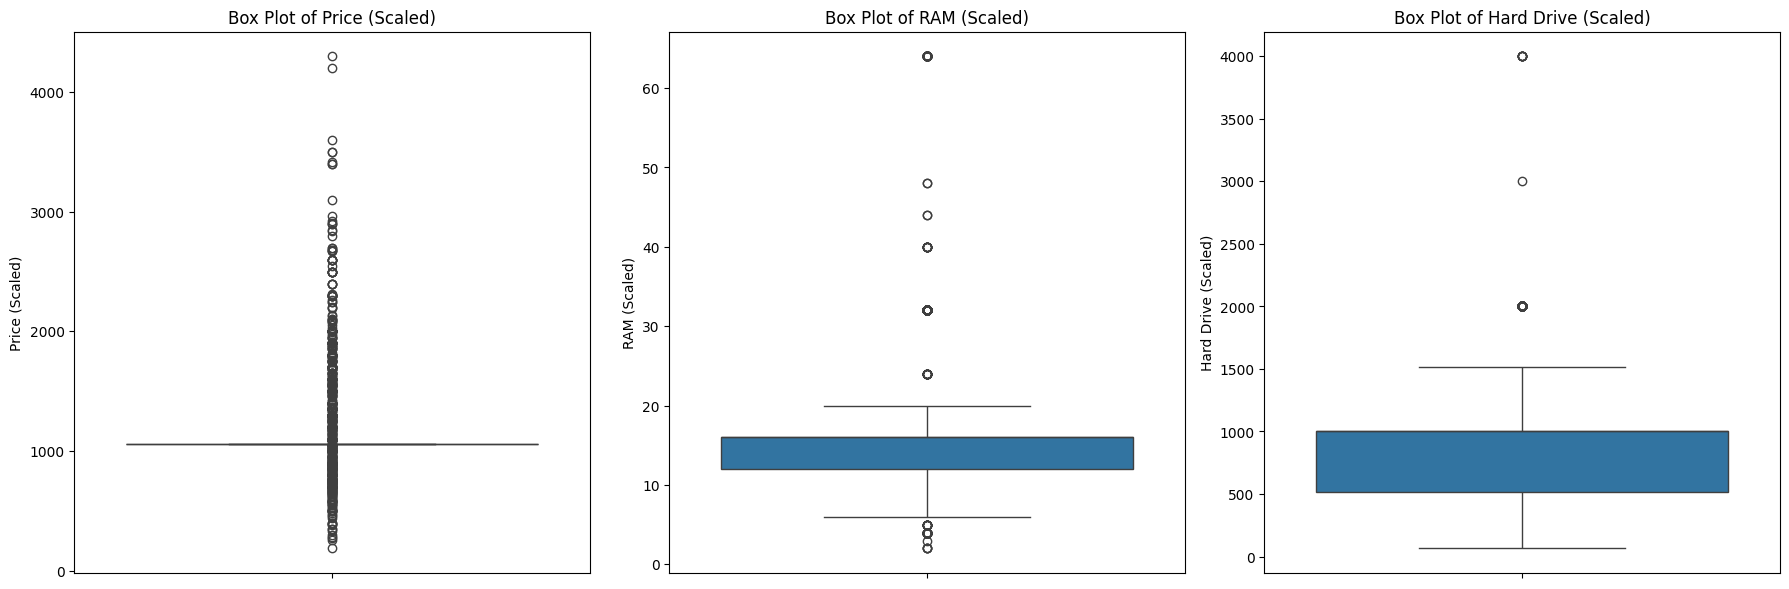

In [ ]:
#outlier
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat sebuah figure dengan 3 area grafik (subplot)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Box plot for 'price'
sns.boxplot(y=laptop_features_df['price'], ax=axes[0])
axes[0].set_title('Box Plot of Price (Scaled)')
axes[0].set_ylabel('Price (Scaled)')

# Box plot for 'RAM'
sns.boxplot(y=laptop_features_df['RAM'], ax=axes[1])
axes[1].set_title('Box Plot of RAM (Scaled)')
axes[1].set_ylabel('RAM (Scaled)')

# Box plot for 'Hard_Drive'
sns.boxplot(y=laptop_features_df['Hard_Drive'], ax=axes[2])
axes[2].set_title('Box Plot of Hard Drive (Scaled)')
axes[2].set_ylabel('Hard Drive (Scaled)')

plt.tight_layout()

---
## 12. Normalisasi Fitur Numerik (Min-Max Scaling)

Menormalisasi kolom numerik ke rentang [0, 1] agar setiap fitur memiliki bobot yang setara dalam proses clustering.

In [ ]:
# Kolom numerik yang akan dinormalisasi
cols_to_scale = ['price', 'RAM', 'Hard_Drive']

# Buat object minmax yang disebut scaler
scaler = MinMaxScaler()

# Menerapkan Min-Max Scaling: nilai diubah ke rentang 0-1
laptop_features_df[cols_to_scale] = scaler.fit_transform(laptop_features_df[cols_to_scale])

print("Hasil normalisasi kolom:", cols_to_scale)
display(laptop_features_df.head())

Hasil normalisasi kolom: ['price', 'RAM', 'Hard_Drive']


,parent_asin,price,brand,RAM,Hard_Drive,CPU_Model
0,B003M6SN8U,0.212799,3,0.096774,0.237805,1
1,B003WUXMVY,0.212799,0,0.032258,0.110772,1
2,B004LB4A82,0.212799,20,0.032258,0.174289,2
3,B004PANKIA,0.212799,6,0.032258,0.110772,1
4,B0052F35I2,0.212799,6,0.064516,0.146341,2


---
## 13. Persiapan Data untuk Clustering

Mengubah DataFrame menjadi array numpy dan menghapus kolom identifier (`parent_asin`) yang tidak digunakan sebagai fitur.

In [ ]:
# Membuat salinan untuk proses clustering
data_copy = laptop_features_df.copy()

# Menghapus kolom parent_asin karena bukan fitur numerik untuk clustering
data_copy = data_copy.drop(columns=['parent_asin'])

# Membersihkan spasi pada nama kolom (jika ada)
data_copy.columns = data_copy.columns.str.strip()

# Mengubah dataframe menjadi array numpy sebagai input model clustering
X = data_copy.values

print("Dimensi data input clustering:", X.shape)
display(data_copy.head())

Dimensi data input clustering: (1647, 5)


,price,brand,RAM,Hard_Drive,CPU_Model
0,0.212799,3,0.096774,0.237805,1
1,0.212799,0,0.032258,0.110772,1
2,0.212799,20,0.032258,0.174289,2
3,0.212799,6,0.032258,0.110772,1
4,0.212799,6,0.064516,0.146341,2


---
## 14. K-Medoids Clustering

Mencari jumlah cluster optimal (k=2 hingga k=15) berdasarkan **Silhouette Score** tertinggi.

In [ ]:
# Menyimpan hasil evaluasi tiap nilai k
results = []
best_k     = None
best_score = -1  # Silhouette score terbaik diinisialisasi dengan nilai minimum

# Iterasi percobaan jumlah cluster dari 2 sampai 15
for n_clusters in range(2, 16):

    # Membuat dan melatih model K-Medoids dengan metode PAM dan jarak Euclidean
    kmedoids = KMedoids(
        n_clusters=n_clusters,
        random_state=42,
        method='pam',
        metric='euclidean'
    )
    kmedoids.fit(X)

    # Menghitung Silhouette Score (hanya valid jika terdapat lebih dari 1 cluster)
    if len(np.unique(kmedoids.labels_)) > 1:
        sil_score = silhouette_score(X, kmedoids.labels_)
    else:
        sil_score = -1

    results.append({'k': n_clusters, 'silhouette': sil_score})
    print(f"k={n_clusters} | Silhouette Score = {sil_score:.4f}")

    # Menyimpan nilai k dengan Silhouette Score terbaik
    if sil_score > best_score:
        best_score = sil_score
        best_k     = n_clusters

print("\n" + "="*40)
print(f"  K TERBAIK           : {best_k}")
print(f"  SILHOUETTE TERBAIK  : {best_score:.4f}")
print("="*40)

# Melatih ulang model dengan jumlah cluster terbaik
best_kmedoids = KMedoids(
    n_clusters=best_k,
    random_state=42,
    method='pam',
    metric='euclidean'
)
best_kmedoids.fit(X)
labels = best_kmedoids.labels_

# Menambahkan label cluster ke dataset produk laptop
laptop_features_df['Cluster'] = labels

# Mengelompokkan indeks data berdasarkan cluster
clusters = {i: [] for i in range(best_k)}
for idx, label in enumerate(labels):
    clusters[label].append(idx)

print("\n--- Anggota Tiap Cluster ---")
for c in clusters:
    print(f"Cluster {c}: {len(clusters[c])} produk")

/usr/local/lib/python3.12/dist-packages/sklearn_extra/cluster/_k_medoids.py:297: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


k=2 | Silhouette Score = 0.6720


/usr/local/lib/python3.12/dist-packages/sklearn_extra/cluster/_k_medoids.py:297: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


k=3 | Silhouette Score = 0.6360


/usr/local/lib/python3.12/dist-packages/sklearn_extra/cluster/_k_medoids.py:297: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


k=4 | Silhouette Score = 0.6310


... (19 outputs left out)

k=14 | Silhouette Score = 0.6387


/usr/local/lib/python3.12/dist-packages/sklearn_extra/cluster/_k_medoids.py:297: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


k=15 | Silhouette Score = 0.6415

  K TERBAIK           : 8
  SILHOUETTE TERBAIK  : 0.7049

--- Anggota Tiap Cluster ---
Cluster 0: 390 produk
Cluster 1: 179 produk
Cluster 2: 253 produk
Cluster 3: 239 produk
Cluster 4: 136 produk
Cluster 5: 85 produk
Cluster 6: 85 produk
Cluster 7: 280 produk


/usr/local/lib/python3.12/dist-packages/sklearn_extra/cluster/_k_medoids.py:297: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


---
## 15. Visualisasi Silhouette Score vs Jumlah Cluster

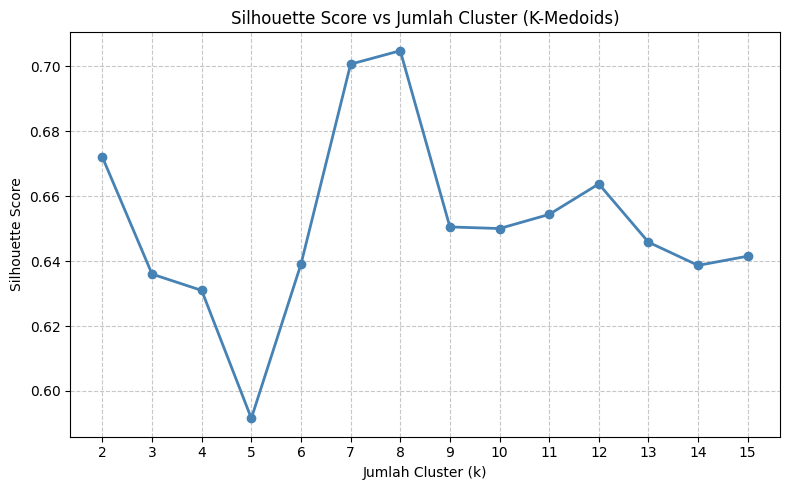

In [ ]:
# Mengambil nilai k dan silhouette score dari hasil evaluasi
k_values   = [r['k']          for r in results]
sil_scores = [r['silhouette'] for r in results]

plt.figure(figsize=(8, 5))
plt.plot(k_values, sil_scores, marker='o', linewidth=2, color='steelblue')
plt.title("Silhouette Score vs Jumlah Cluster (K-Medoids)")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

---
## 16. Analisis Hasil Clustering

Menampilkan statistik deskriptif dan distribusi kategorikal (brand, CPU) untuk setiap cluster.

In [ ]:
# Menambahkan label cluster ke data asli (sebelum normalisasi) untuk analisis
data_asli['Cluster'] = labels

# --- Statistik deskriptif fitur numerik per cluster ---
print("=== Statistik Numerik per Cluster ===\n")
numeric_summary = []

for cluster in sorted(data_asli['Cluster'].unique()):
    cluster_data = data_asli[data_asli['Cluster'] == cluster]

    # Menghitung statistik deskriptif untuk kolom numerik
    desc = cluster_data[['price', 'RAM', 'Hard_Drive']].describe().T
    desc = desc.drop(columns=['25%', '50%', '75%'])  # Hapus persentil yang kurang relevan
    desc['Cluster'] = cluster
    numeric_summary.append(desc)

numeric_summary_df = pd.concat(numeric_summary)
display(numeric_summary_df)

=== Statistik Numerik per Cluster ===



,count,mean,std,min,max,Cluster
price,390.0,1161.437923,357.756413,389.56,3599.99,0
RAM,390.0,16.5,10.475274,2.0,64.0,0
Hard_Drive,390.0,809.435897,431.393449,128.0,4000.0,0
price,179.0,1164.992793,380.959597,638.68,3399.0,1
RAM,179.0,19.430168,11.446475,2.0,64.0,1
Hard_Drive,179.0,847.072626,504.833592,64.0,2000.0,1
price,253.0,1099.216166,363.821064,250.89,3499.99,2
RAM,253.0,19.395257,13.923612,4.0,64.0,2
Hard_Drive,253.0,769.865613,491.354653,128.0,4000.0,2
price,239.0,1188.770795,517.50696,278.63,4199.99,3


In [ ]:
# --- Distribusi Brand dan CPU per cluster ---
for cluster in sorted(data_asli['Cluster'].unique()):
    print(f"\n{'='*30}")
    print(f"  Cluster {cluster}")
    print(f"{'='*30}")

    cluster_data = data_asli[data_asli['Cluster'] == cluster]

    print(f"  Jumlah produk : {len(cluster_data)}")
    print("\n  Top 5 Brand:")
    print(cluster_data['brand'].value_counts().head(5).to_string())

    print("\n  Top 5 CPU Model:")
    print(cluster_data['CPU_Model'].value_counts().head(5).to_string())


  Cluster 0
  Jumlah produk : 390

  Top 5 Brand:
brand
ASUS         203
Acer         126
Alienware     59
Apple          2

  Top 5 CPU Model:
CPU_Model
Core i7    277
Core i5     87
Core i9     24
Core i3      2

  Cluster 1
  Jumlah produk : 179

  Top 5 Brand:
brand
Msi          169
Microsoft      8
Powerspec      1
Maingear       1

  Top 5 CPU Model:
CPU_Model
Core i7    137
Core i5     32
Core i9      9
Core i3      1

  Cluster 2
  Jumlah produk : 253

  Top 5 Brand:
brand
Lenovo       243
Lg             8
Ibuypower      1
Maingear       1

  Top 5 CPU Model:
CPU_Model
Core i7    205
Core i5     40
Core i9      6
Core i3      2

  Cluster 3
  Jumlah produk : 239

  Top 5 Brand:
brand
Dell                     171
Computer Upgrade King     51
Eluktronics               14
Cyberpowerpc               2
Dynabook                   1

  Top 5 CPU Model:
CPU_Model
Core i7    181
Core i5     26
Core i9     26
Ryzen 7      5
Core i3      1

  Cluster 4
  Jumlah produk : 136

  Top 5 Bran

---
## 17. Visualisasi Scatter Plot Hasil Clustering

Menampilkan distribusi data tiap cluster menggunakan 2 fitur pertama (price dan RAM).
Tanda `X` besar menunjukkan posisi medoid masing-masing cluster.

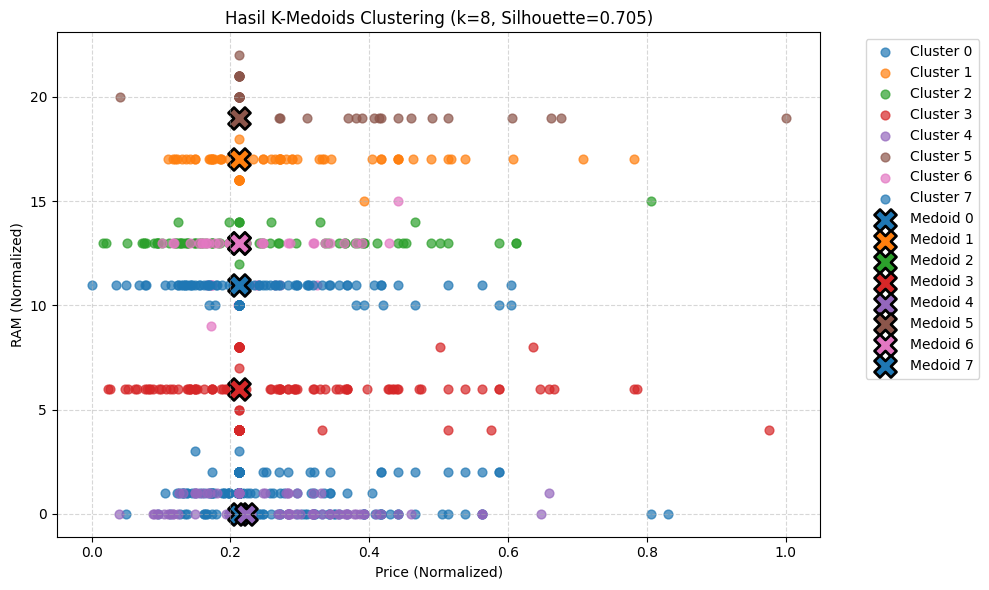

In [ ]:
# Mengambil posisi medoid dari model terbaik
medoid_indices = best_kmedoids.medoid_indices_
medoids        = X[medoid_indices]

# Palet warna untuk tiap cluster
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red',
          'tab:purple', 'tab:brown', 'tab:pink']

plt.figure(figsize=(10, 6))

# Menggambar scatter plot tiap cluster
for cluster_id in range(best_k):
    cluster_points = X[labels == cluster_id]
    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        s=40,
        color=colors[cluster_id % len(colors)],
        label=f'Cluster {cluster_id}',
        alpha=0.7
    )

# Menandai posisi medoid tiap cluster
for i, medoid in enumerate(medoids):
    plt.scatter(
        medoid[0], medoid[1],
        s=250,
        marker='X',
        color=colors[i % len(colors)],
        edgecolor='black',
        linewidth=2,
        label=f'Medoid {i}'
    )

plt.title(f'Hasil K-Medoids Clustering (k={best_k}, Silhouette={best_score:.3f})')
plt.xlabel('Price (Normalized)')
plt.ylabel('RAM (Normalized)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()